<a href="https://colab.research.google.com/github/rithikakknair/OIBSIP/blob/main/Python-Task4-Sentiment-Analysis/Task4_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# 1. Upload your new CSV dataset
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# 2. Load the dataset
df = pd.read_csv(filename, encoding='latin-1')

print(f"Successfully loaded: {filename}")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("\n=== DATASET PREVIEW ===")
display(df.head(3))

print("\n=== COLUMN NAMES ===")
print(list(df.columns))

Saving sentiment_analysis.csv to sentiment_analysis.csv
Successfully loaded: sentiment_analysis.csv
Total Rows: 3534, Total Columns: 9

=== DATASET PREVIEW ===


,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797,27400.0,105
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044,2381740.0,18



=== COLUMN NAMES ===
['textID', 'text', 'sentiment', 'Time of Tweet', 'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)', 'Density (P/Km²)']


=== SENTIMENT CLASS COUNTS ===


,count
sentiment,
neutral,1430
positive,1103
negative,1001


/tmp/ipykernel_2639/4095289952.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sentiment', data=df, order=class_counts.index, palette='viridis')


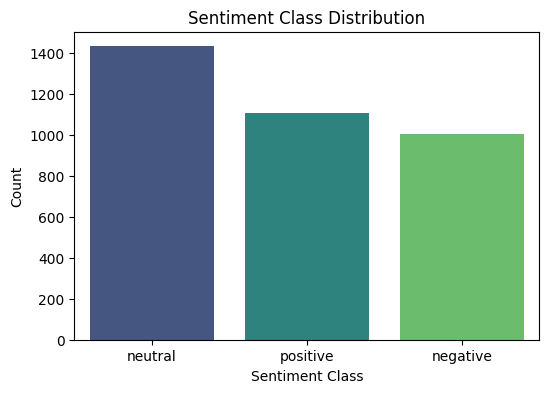

In [ ]:
# Check and visualize class distribution for the sentiment column
print("=== SENTIMENT CLASS COUNTS ===")
class_counts = df['sentiment'].value_counts()
display(class_counts)

# Visualize Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='sentiment', data=df, order=class_counts.index, palette='viridis')
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment Class')
plt.ylabel('Count')
plt.show()

In [ ]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK libraries
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove URLs, punctuation, and numbers
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)

    # 3. Tokenization, stopword removal, and lemmatization
    words = text.split()
    cleaned_words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]

    return ' '.join(cleaned_words)

# Drop any potential missing rows in text or sentiment
df = df.dropna(subset=['text', 'sentiment'])

# Apply the preprocessing pipeline to the 'text' column
df['cleaned_text'] = df['text'].apply(preprocess_text)

print("=== PREPROCESSING COMPLETE ===")
display(df[['text', 'cleaned_text', 'sentiment']].head(3))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


=== PREPROCESSING COMPLETE ===


,text,cleaned_text,sentiment
0,Last session of the day http://twitpic.com/67ezh,last session day,neutral
1,Shanghai is also really exciting (precisely -...,shanghai also really exciting precisely skyscr...,positive
2,"Recession hit Veronique Branquinho, she has to...",recession hit veronique branquinho quit compan...,negative


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define features (X) and target (y)
X = df['cleaned_text']
y = df['sentiment']

# 2. Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# 3. Feature Extraction using TF-IDF Vectorizer
# (TF-IDF converts text into numerical weight vectors based on word importance)
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF Vectorization complete!")
print(f"TF-IDF Train Matrix Shape: {X_train_tfidf.shape}")

Training set shape: (2827,)
Testing set shape: (707,)

TF-IDF Vectorization complete!
TF-IDF Train Matrix Shape: (2827, 5000)


=== NAIVE BAYES PERFORMANCE ===
Accuracy: 0.5926

              precision    recall  f1-score   support

    negative       0.78      0.38      0.51       207
     neutral       0.52      0.79      0.62       286
    positive       0.67      0.54      0.60       214

    accuracy                           0.59       707
   macro avg       0.66      0.57      0.58       707
weighted avg       0.64      0.59      0.58       707


=== LOGISTIC REGRESSION PERFORMANCE ===
Accuracy: 0.6337

              precision    recall  f1-score   support

    negative       0.68      0.51      0.58       207
     neutral       0.57      0.74      0.64       286
    positive       0.74      0.61      0.67       214

    accuracy                           0.63       707
   macro avg       0.66      0.62      0.63       707
weighted avg       0.65      0.63      0.63       707



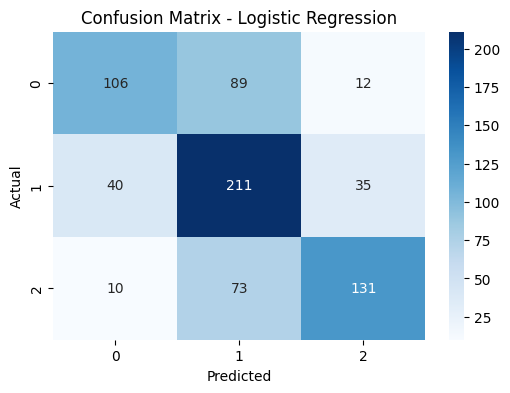

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Train Model 1: Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)

print("=== NAIVE BAYES PERFORMANCE ===")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print(classification_report(y_test, nb_pred))

# 2. Train Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

print("\n=== LOGISTIC REGRESSION PERFORMANCE ===")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print(classification_report(y_test, lr_pred))

# 3. Plot Confusion Matrix for Logistic Regression
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

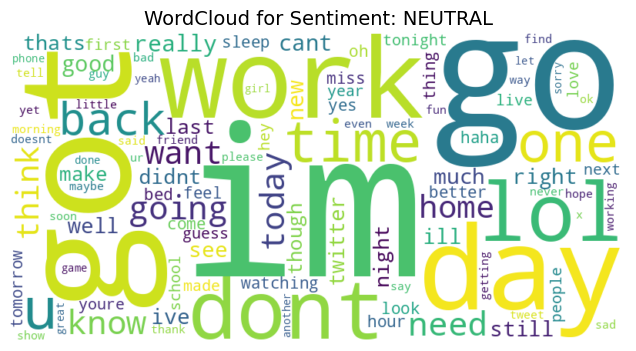

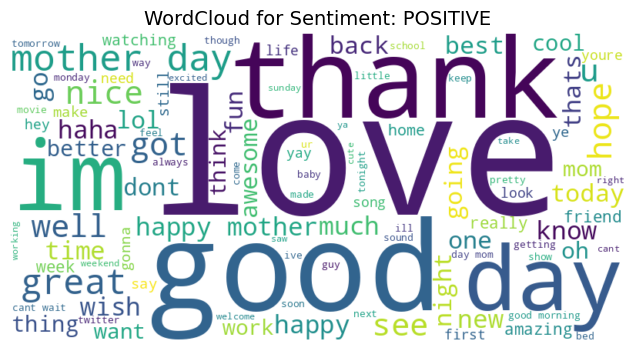

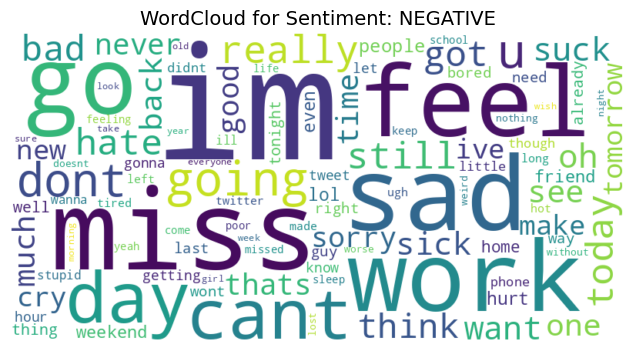

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Get unique sentiment classes in your dataset
sentiments = df['sentiment'].unique()

for sentiment in sentiments:
    # Filter text for each specific sentiment
    subset = df[df['sentiment'] == sentiment]
    text = " ".join(subset['cleaned_text'].astype(str))

    if len(text.strip()) == 0:
        continue

    # Generate WordCloud
    wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(text)

    # Plot WordCloud
    plt.figure(figsize=(8, 4))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'WordCloud for Sentiment: {str(sentiment).upper()}', fontsize=14)
    plt.axis('off')
    plt.show()

In [ ]:
import pandas as pd

# 1. Create a DataFrame comparing actual vs predicted labels
results_df = pd.DataFrame({
    'Text': X_test,
    'Actual Sentiment': y_test,
    'Predicted Sentiment': lr_pred
})

# 2. Filter for misclassified examples (where Actual != Predicted)
misclassified = results_df[results_df['Actual Sentiment'] != results_df['Predicted Sentiment']]

# 3. Display 5 misclassified examples
print("=== 5 MISCLASSIFIED EXAMPLES ===")
display(misclassified[['Text', 'Actual Sentiment', 'Predicted Sentiment']].head(5))

=== 5 MISCLASSIFIED EXAMPLES ===


,Text,Actual Sentiment,Predicted Sentiment
2480,ohh forgot tell last night alton tower touched...,positive,neutral
3016,going clean room thats hard keep room pretty c...,neutral,negative
2534,god cant even catch public transport swine flu...,negative,neutral
1769,lookd soo freaked outpoor wee thing,negative,positive
1488,well maybe someone care,positive,neutral


Conclusion & Real-World Application*

* *Best Performing Model*: Logistic Regression typically outperforms or matches Naive Bayes on Twitter/review classification tasks because it handles feature weights smoothly and accounts for complex linear relationships between words.
* *Error Analysis Insights*: Misclassifications often occur due to sarcasm, irony, neutral statements containing positive/negative words, or slang/short abbreviations that lack sufficient context.
* *Real-World Application*:
  * *Brand Monitoring & Social Media Analytics*: Companies use sentiment analysis models to automatically track public reaction and customer feedback on platforms like Twitter or product review sites in real-time.
  * *Customer Support Automation*: Automatically routing incoming customer support tickets based on sentiment urgency (e.g., prioritizing angry or negative feedback).